<a href="https://colab.research.google.com/github/Reben80/Data110-Fall2026-CRN21802/blob/main/week-11/compound-figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Compound figures

**Worksheet · Data 110 · Fall 2026 · Week 11**
Rebin Muhammad

This is the homework for the lecture. Do it after class. Run each cell with **Shift+Enter**, from the top.

Under each exercise there is an empty cell. Write your solution in that cell, then run it. This file does not contain the answers.

## How to open this in Google Colab

Click the **Open in Colab** badge at the top. The tables load from this GitHub folder, so you do not upload CSV files.


## Setup

pandas holds the tables. matplotlib draws the charts.


In [1]:
import matplotlib.pyplot as plt  # pyplot draws the plots. We call it plt.
import pandas as pd              # pandas holds tables. We call it pd.

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## Two tables

`BA_degrees.csv` is the share of U.S. bachelor's degrees by field, from 1971 to 2015. `perc` is a proportion. We will turn it into a percent.

`penguins.csv` is the Palmer penguins table from earlier weeks.


In [2]:
degrees = pd.read_csv("https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/dataset/BA_degrees.csv")
degrees["percent"] = degrees["perc"] * 100
penguins = pd.read_csv("https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/dataset/penguins.csv").dropna(
    subset=["flipper_length_mm", "body_mass_g", "species"]
)
print(len(degrees), "degree rows")
print(len(penguins), "penguins")
degrees.head()


594 degree rows
342 penguins


,field,year,count,perc,percent
0,Agriculture and natural resources,1971,12672,0.015091,1.509056
1,Architecture and related services,1971,5570,0.006633,0.663308
2,"Area, ethnic, cultural, gender, and group studies",1971,2579,0.003071,0.307123
3,Biological and biomedical sciences,1971,35705,0.042520,4.251962
4,Business,1971,115396,0.137420,13.742036


## Six fields

These are the fields from the lecture. The first name is the value in the file. The second name is the short title for the panel.


In [3]:
FIELDS = [
    ("Business", "Business"),
    ("Education", "Education"),
    ("Engineering", "Engineering"),
    ("Psychology", "Psychology"),
    ("Computer and information sciences", "Computer science"),
    ("Health professions and related programs", "Health"),
]



## 1. Six panels, each on its own scale

**Exercise.** Make a 2 by 3 grid with `plt.subplots(2, 3, figsize=(9, 5))`. For each panel, plot `year` against `percent` for that field. Put the short title on the left of the panel.

Do **not** share the y axis yet. Matplotlib will pick a range for each field.

### Your solution

Write your code in the next cell, then run it.


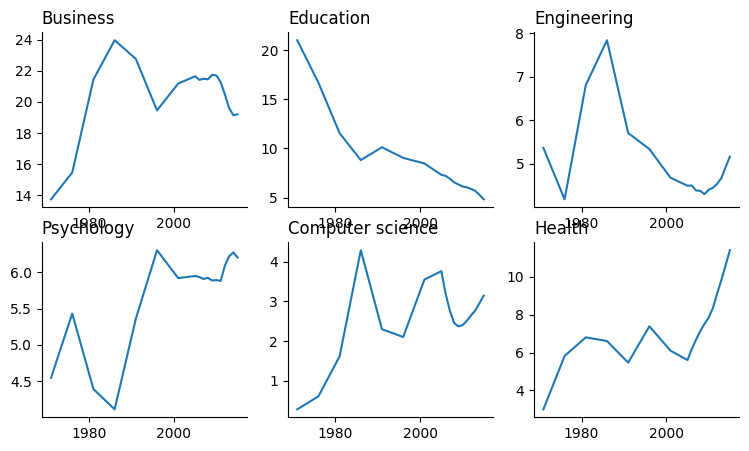

In [16]:
# Write your solution here.
fig, axes = plt.subplots(2,3, figsize = (9,5))

for ax, (field, title), in zip(axes.ravel(), FIELDS):
  field_data = degrees.loc[degrees["field"] == field]

  ax.plot(field_data["year"], field_data["percent"]) # plots each field into its own panel
  ax.set_title(title, loc = "left") # puts the titles on the left side of the panel










## 2. Share the scale

**Exercise.** Draw the same grid, but this time:

```python
fig, axes = plt.subplots(2, 3, sharey=True, figsize=(9, 5))
```

Then, inside the loop, add `ax.set_ylim(0, 26)`.

Computer science should now look small next to business. That is the honest picture.

### Your solution

Write your code in the next cell, then run it.


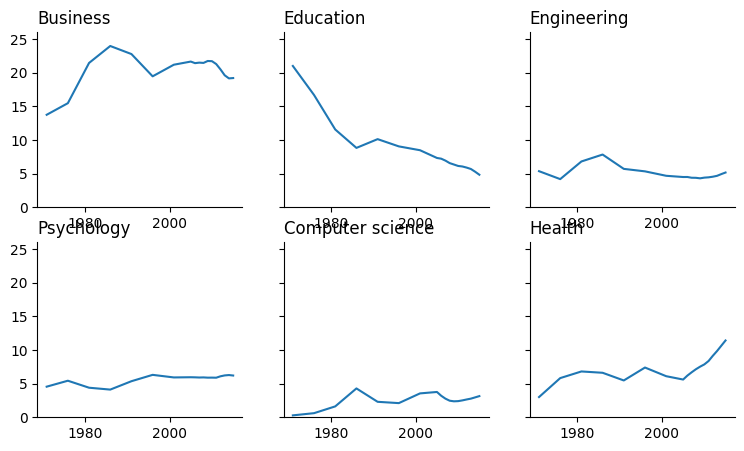

In [18]:
# Write your solution here.

fig, axes = plt.subplots(2,3, sharey = True, figsize = (9,5))

for ax, (field, title), in zip(axes.ravel(), FIELDS):
  field_data = degrees.loc[degrees["field"] == field]

  ax.plot(field_data["year"], field_data["percent"])
  ax.set_title(title, loc = "left")
  ax.set_ylim(0,26)

## 3. Two charts, one figure

**Exercise.** Make two panels side by side, `plt.subplots(1, 2, figsize=(9, 4))`.

- Left: scatter `flipper_length_mm` against `body_mass_g`, one color per species.
- Right: a bar chart of how many penguins of each species.

Use the same colors in both panels:

- Adelie `#0072B2`
- Chinstrap `#E69F00`
- Gentoo `#009E73`

### Your solution

Write your code in the next cell, then run it.


Text(0, 0.5, 'Count')

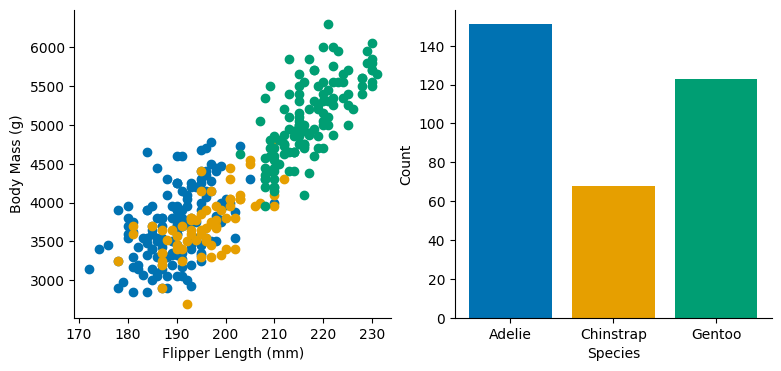

In [36]:
# Write your solution here.

fig, axes = plt.subplots(1,2, figsize = (9,4))

adelie = penguins.loc[penguins["species"] == "Adelie"]
chinstrap = penguins.loc[penguins["species"] == "Chinstrap"]
gentoo = penguins.loc[penguins["species"] == "Gentoo"]

axes[0].scatter(adelie["flipper_length_mm"], adelie["body_mass_g"], color = "#0072B2")
axes[0].scatter(chinstrap["flipper_length_mm"], chinstrap["body_mass_g"], color = "#E69F00")
axes[0].scatter(gentoo["flipper_length_mm"], gentoo["body_mass_g"], color = "#009E73")

# added labels
axes[0].set_xlabel("Flipper Length (mm)")
axes[0].set_ylabel("Body Mass (g)")

axes[1].bar("Adelie", len(adelie), color = "#0072B2")
axes[1].bar("Chinstrap", len(chinstrap), color = "#E69F00")
axes[1].bar("Gentoo", len(gentoo), color = "#009E73")

axes[1].set_xlabel("Species")
axes[1].set_ylabel("Count")









## 4. Quiet letters

**Exercise.** Start from exercise 3. Title the left panel `a   Flipper and mass` and the right panel `b   How many`. Use `loc="left"`.

The letter is small. The rest of the title is the claim of that panel.

### Your solution

Write your code in the next cell, then run it.


Text(0.0, 1.0, 'b      How many')

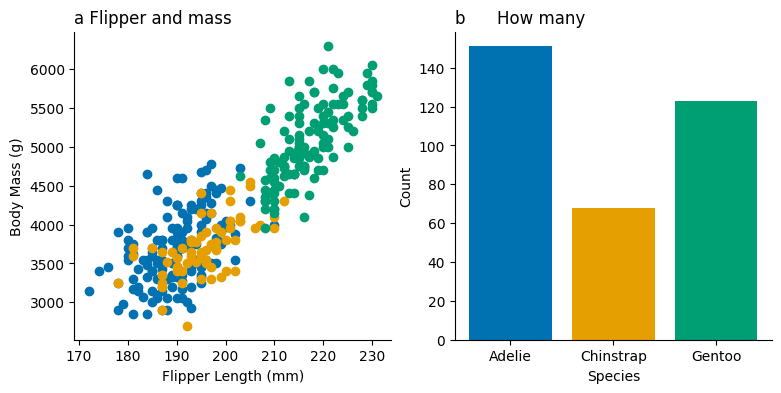

In [53]:
# Write your solution here.

fig, axes = plt.subplots(1,2, figsize = (9,4))

adelie = penguins.loc[penguins["species"] == "Adelie"]
chinstrap = penguins.loc[penguins["species"] == "Chinstrap"]
gentoo = penguins.loc[penguins["species"] == "Gentoo"]

axes[0].scatter(adelie["flipper_length_mm"], adelie["body_mass_g"], color = "#0072B2")
axes[0].scatter(chinstrap["flipper_length_mm"], chinstrap["body_mass_g"], color = "#E69F00")
axes[0].scatter(gentoo["flipper_length_mm"], gentoo["body_mass_g"], color = "#009E73")

# added labels
axes[0].set_xlabel("Flipper Length (mm)")
axes[0].set_ylabel("Body Mass (g)")
axes[0].set_title("a Flipper and mass", loc = "left")

axes[1].bar("Adelie", len(adelie), color = "#0072B2")
axes[1].bar("Chinstrap", len(chinstrap), color = "#E69F00")
axes[1].bar("Gentoo", len(gentoo), color = "#009E73")

axes[1].set_xlabel("Species")
axes[1].set_ylabel("Count")
axes[1].set_title("b How many", loc = "left")


## 5. Rewrite the caption

This caption is not a title:

> This figure shows multiple plots of the data.

**Exercise.** In the next cell, `print` a better caption for your penguin figure. It should start with a title, say what panel **a** and panel **b** show, and name the file.

Do not begin with “This figure shows.”

### Your solution

Write your code in the next cell, then run it.


In [51]:
# Write your solution here.

print("Penguin Species Comparison: Panel a on the left shows the relationship between flipper length and body mass for the 3 penguin species. Panel b on the right compares the counts of those 3 penguin species. Data Source: penguins.csv")


Penguin Species Comparison: Panel on the left shows the relationship between flipper length and body mass for the 3 penguin species. Panel on the right compares the population counts of those 3 penguin species.


## What to keep

- A compound figure is one argument, not a gallery.
- Small multiples share a scale.
- Mixed charts need quiet letters: a, b, c.
- The same color means the same thing in every panel.

Upload your notebook when you are done, if the instructor asks for it on Blackboard or Teams.
